# ⚡ LSTM Energy Forecasting — Overfitting Fixed (v2)

### What changed from v1 and why
| Parameter | v1 (broken) | v2 (fixed) | Reason |
|---|---|---|---|
| `LOOK_BACK` | 24 | **48** | More history → model sees 2 full days, better seasonal context |
| `dropout_rate` | 0.30 | **0.45** | Val R²=0.80 but Test R²=0.43 → severe overfit, need more regularisation |
| `l2_reg` | 1e-4 | **5e-4** | Stronger weight penalty to prevent memorisation |
| `learning_rate` | 1e-3 | **5e-4** | Slower learning → less aggressive fitting to training patterns |
| `BATCH_SIZE` | 32 | **64** | Larger batch → noisier gradients → less overfitting |
| `lstm_units_1` | 128 | **96** | Reduce capacity — model was too large for dataset size |
| `lstm_units_2` | 64 | **48** | Same reason |
| `patience` | 20 | **25** | Give model more time to find the true minimum |
| Training data | train only | **train + val** | After tuning, re-train on all available data before final test eval |


## 1 · Imports & Environment

In [2]:
# ── 1. Imports ────────────────────────────────────────────────────────────────
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow  : {tf.__version__}")
print(f"GPU devices : {gpus if gpus else 'None — running on CPU'}")
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

pd.set_option("display.float_format", "{:.4f}".format)
print("\nEnvironment ready ✓")


TensorFlow  : 2.21.0
GPU devices : None — running on CPU

Environment ready ✓


## 2 · Load Data & Chronological Split

In [3]:
# ── 2. Load & Split ───────────────────────────────────────────────────────────
DATA_PATH  = "../data/processed/final_feature_engineered_dataset.csv"
TARGET_COL = "energy_kwh.1"

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.set_index("timestamp").sort_index()

print(f"Dataset shape : {df.shape}")
print(f"Date range    : {df.index.min()}  →  {df.index.max()}")
print(f"Target        : '{TARGET_COL}'")

# ── Chronological 70 / 15 / 15 split ─────────────────────────────────────────
# Increased val to 15% so the model sees more diverse validation patterns
n         = len(df)
TRAIN_END = int(n * 0.70)
VAL_END   = int(n * 0.85)

train_df    = df.iloc[:TRAIN_END]
val_df      = df.iloc[TRAIN_END:VAL_END]
test_df     = df.iloc[VAL_END:]
trainval_df = df.iloc[:VAL_END]    # train+val combined for final retraining

print(f"\nSplit summary (70 / 15 / 15):")
print(f"  Train    : {len(train_df):>5} rows  ({train_df.index[0]}  →  {train_df.index[-1]})")
print(f"  Val      : {len(val_df):>5} rows  ({val_df.index[0]}  →  {val_df.index[-1]})")
print(f"  Test     : {len(test_df):>5} rows  ({test_df.index[0]}  →  {test_df.index[-1]})")
print(f"  Train+Val: {len(trainval_df):>5} rows  (used for final model retraining)")


Dataset shape : (2088, 51)
Date range    : 2025-09-22 18:00:00  →  2026-02-26 12:00:00
Target        : 'energy_kwh.1'

Split summary (70 / 15 / 15):
  Train    :  1461 rows  (2025-09-22 18:00:00  →  2026-01-24 14:00:00)
  Val      :   313 rows  (2026-01-24 15:00:00  →  2026-02-07 06:00:00)
  Test     :   314 rows  (2026-02-07 07:00:00  →  2026-02-26 12:00:00)
  Train+Val:  1774 rows  (used for final model retraining)


## 3 · Feature Selection & Scaling

In [4]:
# ── 3. Feature Selection ─────────────────────────────────────────────────────
# Rank features by |Pearson r| with target — fit on TRAIN only
CORR_THRESHOLD = 0.05

corr_series = (
    train_df.corr()[TARGET_COL]
    .drop(TARGET_COL)
    .abs()
    .sort_values(ascending=False)
)

FEATURE_COLS = corr_series[corr_series >= CORR_THRESHOLD].index.tolist()
print(f"Selected features : {len(FEATURE_COLS)}  (|r| >= {CORR_THRESHOLD})")
print(f"Dropped           : {df.shape[1] - 1 - len(FEATURE_COLS)} low-signal features")
print(f"\nTop-15 by |r|:")
for i, (feat, val) in enumerate(corr_series[FEATURE_COLS].head(15).items(), 1):
    print(f"  {i:>2}. {feat:<30} r = {val:.4f}")


Selected features : 44  (|r| >= 0.05)
Dropped           : 6 low-signal features

Top-15 by |r|:
   1. ewm_alpha_05                   r = 0.7446
   2. lag_1                          r = 0.7330
   3. ewm_alpha_02                   r = 0.6647
   4. lag_2                          r = 0.6531
   5. rolling_mean_6                 r = 0.6432
   6. rolling_std_12                 r = 0.5711
   7. rolling_mean_24                r = 0.5681
   8. lag_3                          r = 0.5681
   9. rolling_std_24                 r = 0.5661
  10. index_thsw                     r = 0.5549
  11. out_temp                       r = 0.5497
  12. rolling_std_6                  r = 0.5144
  13. rolling_mean_12                r = 0.5098
  14. lag_24                         r = 0.4621
  15. pt_dew                         r = 0.4444


In [5]:
# ── 4. Robust Scaling ────────────────────────────────────────────────────────
# Fit scalers on TRAIN only — no leakage into val/test
feature_scaler = RobustScaler()
target_scaler  = RobustScaler()

X_train_sc = feature_scaler.fit_transform(train_df[FEATURE_COLS])
y_train_sc = target_scaler.fit_transform(train_df[[TARGET_COL]])

X_val_sc   = feature_scaler.transform(val_df[FEATURE_COLS])
y_val_sc   = target_scaler.transform(val_df[[TARGET_COL]])

X_test_sc  = feature_scaler.transform(test_df[FEATURE_COLS])
y_test_sc  = target_scaler.transform(test_df[[TARGET_COL]])

# Train+Val combined (for final retraining step)
X_trainval_sc = feature_scaler.transform(trainval_df[FEATURE_COLS])
y_trainval_sc = target_scaler.transform(trainval_df[[TARGET_COL]])

print(f"X_train : {X_train_sc.shape}  |  X_val : {X_val_sc.shape}  |  X_test : {X_test_sc.shape}")
print("Scaling complete ✓")


X_train : (1461, 44)  |  X_val : (313, 44)  |  X_test : (314, 44)
Scaling complete ✓


## 4 · Sequence Windowing

In [6]:
# ── 5. Sliding Window Sequences ──────────────────────────────────────────────
# LOOK_BACK increased from 24 → 48 (2 full days of history)
# This is the single biggest fix — model now sees 2 daily cycles before predicting

LOOK_BACK = 48    # ← was 24, now 48 (2 days)
HORIZON   = 1

def make_sequences(X, y, look_back, horizon=1):
    Xs, ys = [], []
    for i in range(look_back, len(X) - horizon + 1):
        Xs.append(X[i - look_back : i])
        ys.append(y[i : i + horizon, 0])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

X_tr, y_tr = make_sequences(X_train_sc,    y_train_sc,    LOOK_BACK)
X_va, y_va = make_sequences(X_val_sc,      y_val_sc,      LOOK_BACK)
X_te, y_te = make_sequences(X_test_sc,     y_test_sc,     LOOK_BACK)
X_tv, y_tv = make_sequences(X_trainval_sc, y_trainval_sc, LOOK_BACK)

print(f"Sequence shapes (LOOK_BACK={LOOK_BACK}):")
print(f"  Train    : X={X_tr.shape}  y={y_tr.shape}")
print(f"  Val      : X={X_va.shape}  y={y_va.shape}")
print(f"  Test     : X={X_te.shape}  y={y_te.shape}")
print(f"  Train+Val: X={X_tv.shape}  y={y_tv.shape}")
print(f"\nInput to LSTM : (batch, {LOOK_BACK} timesteps, {X_tr.shape[2]} features)")


Sequence shapes (LOOK_BACK=48):
  Train    : X=(1413, 48, 44)  y=(1413, 1)
  Val      : X=(265, 48, 44)  y=(265, 1)
  Test     : X=(266, 48, 44)  y=(266, 1)
  Train+Val: X=(1726, 48, 44)  y=(1726, 1)

Input to LSTM : (batch, 48 timesteps, 44 features)


## 5 · Model Architecture (Regularised)

In [7]:
# ── 6. Build Model ────────────────────────────────────────────────────────────
# Key changes vs v1:
#   dropout 0.30 → 0.45   (stronger regularisation)
#   l2_reg  1e-4 → 5e-4   (stronger weight penalty)
#   units reduced          (less capacity = less memorisation)
#   lr      1e-3 → 5e-4   (slower, more careful learning)

def build_lstm_model(
    input_shape,
    lstm_units_1  = 96,      # ← was 128
    lstm_units_2  = 48,      # ← was 64
    dense_units   = 32,
    dropout_rate  = 0.45,    # ← was 0.30
    l2_reg        = 5e-4,    # ← was 1e-4
    learning_rate = 5e-4,    # ← was 1e-3
):
    inp = keras.Input(shape=input_shape, name="input_sequence")

    # ── BiLSTM Layer 1 ────────────────────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(
            lstm_units_1,
            return_sequences=True,
            kernel_regularizer=regularizers.l2(l2_reg),
            recurrent_regularizer=regularizers.l2(l2_reg / 2),
        ),
        name="biLSTM_1"
    )(inp)
    x = layers.LayerNormalization(name="layernorm_1")(x)
    x = layers.Dropout(dropout_rate, name="dropout_1")(x)

    # ── BiLSTM Layer 2 ────────────────────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(
            lstm_units_2,
            return_sequences=True,
            kernel_regularizer=regularizers.l2(l2_reg),
            recurrent_regularizer=regularizers.l2(l2_reg / 2),
        ),
        name="biLSTM_2"
    )(x)
    x = layers.LayerNormalization(name="layernorm_2")(x)
    x = layers.Dropout(dropout_rate, name="dropout_2")(x)

    # ── Attention ─────────────────────────────────────────────────────────────
    attn_scores  = layers.Dense(1, activation="tanh", name="attn_score")(x)
    attn_weights = layers.Softmax(axis=1, name="attn_weights")(attn_scores)
    context      = layers.Multiply(name="attn_context")([x, attn_weights])
    context      = layers.Lambda(
                       lambda t: tf.reduce_sum(t, axis=1),
                       name="attn_sum"
                   )(context)

    # ── Dense Head ────────────────────────────────────────────────────────────
    x   = layers.Dense(
              dense_units, activation="relu",
              kernel_regularizer=regularizers.l2(l2_reg),
              name="dense_1"
          )(context)
    x   = layers.Dropout(dropout_rate / 2, name="dropout_3")(x)
    out = layers.Dense(1, name="output")(x)

    model = keras.Model(inputs=inp, outputs=out)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="huber",
        metrics=["mae"],
    )
    return model

INPUT_SHAPE = (LOOK_BACK, X_tr.shape[2])
model = build_lstm_model(INPUT_SHAPE)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_sequence (InputLayer)   │ (None, 48, 44)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ biLSTM_1 (Bidirectional)      │ (None, 48, 192)           │         108,288 │ input_sequence[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layernorm_1                   │ (None, 48, 192)           │             384 │ biLSTM_1[0][0]             │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 48, 192)           │               0 │ layernorm_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ biLSTM_2 (Bidirectional)      │ (None, 48, 96)            │          92,544 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layernorm_2                   │ (None, 48, 96)            │             192 │ biLSTM_2[0][0]             │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 48, 96)            │               0 │ layernorm_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_score (Dense)            │ (None, 48, 1)             │              97 │ dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_weights (Softmax)        │ (None, 48, 1)             │               0 │ attn_score[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_context (Multiply)       │ (None, 48, 96)            │               0 │ dropout_2[0][0],           │
│                               │                           │                 │ attn_weights[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_sum (Lambda)             │ (None, 96)                │               0 │ attn_context[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 32)                │           3,104 │ attn_sum[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 32)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output (Dense)                │ (None, 1)                 │              33 │ dropout_3[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 204,642 (799.38 KB)

 Trainable params: 204,642 (799.38 KB)

 Non-trainable params: 0 (0.00 B)

## 6 · Training

In [8]:
# ── 7. Train Phase 1 : Train set only (for tuning & diagnostics) ──────────────
os.makedirs("../models/checkpoints", exist_ok=True)

EPOCHS     = 200   # more budget, early stopping handles actual stop
BATCH_SIZE = 64    # ← was 32; larger batch = less overfitting

cb_list = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=25,              # ← was 20; more patient
        restore_best_weights=True,
        verbose=1,
    ),
    callbacks.ModelCheckpoint(
        filepath="../models/checkpoints/lstm_best_v2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=12,
        min_lr=1e-7,
        verbose=1,
    ),
    callbacks.CSVLogger("../outputs/logs/training_log_v2.csv"),
]

print(f"Training config (v2 — overfitting fixes applied):")
print(f"  LOOK_BACK  : {LOOK_BACK}  (was 24)")
print(f"  Epochs     : {EPOCHS} (patience={25})")
print(f"  Batch size : {BATCH_SIZE}  (was 32)")
print(f"  Dropout    : 0.45  (was 0.30)")
print(f"  L2 reg     : 5e-4  (was 1e-4)")
print(f"  LR         : 5e-4  (was 1e-3)")

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    shuffle=False,        # NEVER shuffle time-series
    verbose=1,
)

best_epoch = np.argmin(history.history["val_loss"]) + 1
print(f"\n✅ Phase 1 training complete")
print(f"   Best epoch    : {best_epoch}")
print(f"   Best val_loss : {min(history.history['val_loss']):.6f}")
print(f"   Best val_mae  : {history.history['val_mae'][best_epoch-1]:.4f}")


Training config (v2 — overfitting fixes applied):
  LOOK_BACK  : 48  (was 24)
  Epochs     : 200 (patience=25)
  Batch size : 64  (was 32)
  Dropout    : 0.45  (was 0.30)
  L2 reg     : 5e-4  (was 1e-4)
  LR         : 5e-4  (was 1e-3)
Epoch 1/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 12s 159ms/step - loss: 0.6614 - mae: 0.6450 - val_loss: 0.5360 - val_mae: 0.5041 - learning_rate: 5.0000e-04
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - loss: 0.6998 - mae: 0.6814 - val_loss: 0.5404 - val_mae: 0.5162 - learning_rate: 5.0000e-04
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - loss: 0.5966 - mae: 0.5818 - val_loss: 0.5381 - val_mae: 0.5151 - learning_rate: 5.0000e-04
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - loss: 0.5846 - mae: 0.5436 - val_loss: 0.5069 - val_mae: 0.4903 - learning_rate: 5.0000e-04
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - loss: 0.5666 - mae: 0.5605 - val_loss: 0.5192 - val_mae: 0.5046 - learning_rate: 5.0000e-04
Epoch 6/200
23/23 ━━━━━━━━━━━

## 7 · Phase 2 — Retrain on Full Train+Val Data

In [10]:
# ── 8. Phase 2 : Retrain on Train+Val combined ───────────────────────────────
# Why? After hyperparameter tuning is done using val set,
# we retrain on ALL available data (train+val) so the final model
# has seen more examples before being evaluated on test.
# Use best_epoch from Phase 1 as the fixed number of epochs (no early stop).

print(f"Retraining on Train+Val ({len(X_tv)} sequences) for {best_epoch} epochs...")
print("(No early stopping — using best_epoch from Phase 1 as fixed budget)")

# Rebuild fresh model with same architecture
model_final = build_lstm_model(INPUT_SHAPE)

cb_final = [
    callbacks.ModelCheckpoint(
        filepath="../models/checkpoints/lstm_final_v2.keras",
        monitor="loss",          # monitor train loss (no val set here)
        save_best_only=True,
        verbose=0,
    ),
    callbacks.CSVLogger("../outputs/logs/training_log_final_v2.csv"),
]

history_final = model_final.fit(
    X_tv, y_tv,
    epochs=best_epoch,           # fixed to best epoch from Phase 1
    batch_size=BATCH_SIZE,
    callbacks=cb_final,
    shuffle=False,
    verbose=1,
)

print(f"\n✅ Phase 2 retraining complete")
print(f"   Final train loss : {history_final.history['loss'][-1]:.6f}")


Retraining on Train+Val (1726 sequences) for 128 epochs...
(No early stopping — using best_epoch from Phase 1 as fixed budget)
Epoch 1/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - loss: 0.6599 - mae: 0.6398
Epoch 2/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.6658 - mae: 0.6493 
Epoch 3/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - loss: 0.6266 - mae: 0.6048 
Epoch 4/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 0.5954 - mae: 0.5643 
Epoch 5/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.6011 - mae: 0.5652 
Epoch 6/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.5640 - mae: 0.5278
Epoch 7/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.5160 - mae: 0.4564 
Epoch 8/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.4999 - mae: 0.4535 
Epoch 9/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.4933 - mae: 0.4354 
Epoch 10/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.4675 - mae: 0.4062 
Epoch 11/128
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step -

## 8 · Evaluation on Test Set

In [11]:
# ── 9. Evaluate final model on Test Set ──────────────────────────────────────
def get_metrics(y_true, y_pred, label=""):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-3, None))) * 100
    return {"label": label, "R2": r2, "RMSE": rmse, "MAE": mae, "MAPE": mape}

def predict_inverse(mdl, X, y_scaled):
    pred_sc = mdl.predict(X, batch_size=BATCH_SIZE, verbose=0)
    pred    = target_scaler.inverse_transform(pred_sc).flatten()
    true    = target_scaler.inverse_transform(y_scaled).flatten()
    return true, pred

# Phase 1 model (train-only) — for comparison
p1_true, p1_pred = predict_inverse(model,       X_te, y_te)
# Phase 2 model (train+val)  — final model
p2_true, p2_pred = predict_inverse(model_final, X_te, y_te)

# Also get train metrics for Phase 2
p2_tr_true, p2_tr_pred = predict_inverse(model_final, X_tr, y_tr)
# Val metrics from Phase 1
p1_va_true, p1_va_pred = predict_inverse(model, X_va, y_va)

m_p1_test  = get_metrics(p1_true,    p1_pred,    "Phase1 Test")
m_p2_test  = get_metrics(p2_true,    p2_pred,    "Phase2 Test (FINAL)")
m_p2_train = get_metrics(p2_tr_true, p2_tr_pred, "Phase2 Train")
m_p1_val   = get_metrics(p1_va_true, p1_va_pred, "Phase1 Val")

# Use phase 2 as primary results
y_true = p2_true
y_pred = p2_pred
rmse   = m_p2_test["RMSE"]
mae    = m_p2_test["MAE"]
r2     = m_p2_test["R2"]
mape   = m_p2_test["MAPE"]

print("=" * 62)
print("            FINAL MODEL PERFORMANCE (v2)")
print("=" * 62)
print(f"  {'Model':<25} {'R²':>8} {'RMSE':>8} {'MAE':>8} {'MAPE':>8}")
print(f"  {'-'*58}")
for m in [m_p1_val, m_p1_test, m_p2_train, m_p2_test]:
    print(f"  {m['label']:<25} {m['R2']:>8.4f} {m['RMSE']:>8.2f} {m['MAE']:>8.2f} {m['MAPE']:>7.1f}%")
print("=" * 62)

r2_gap = m_p2_train["R2"] - m_p2_test["R2"]
print(f"\n  R² gap (Train − Test) : {r2_gap:+.4f}", end="  ")
if   r2_gap < 0.05: print("✅ No overfitting")
elif r2_gap < 0.10: print("⚠️  Mild overfitting")
elif r2_gap < 0.20: print("🟠 Moderate overfitting")
else:               print("❌ Severe overfitting")

print()
if r2 >= 0.90:   print("🏆 Excellent — R² ≥ 0.90")
elif r2 >= 0.80: print("✅ Good      — R² ≥ 0.80")
elif r2 >= 0.70: print("⚠️  Moderate  — R² ≥ 0.70")
else:            print("❌ Below 0.70 — try tips in next cell")


            FINAL MODEL PERFORMANCE (v2)
  Model                           R²     RMSE      MAE     MAPE
  ----------------------------------------------------------
  Phase1 Val                  0.7649    27.53    17.97    13.0%
  Phase1 Test                 0.5658    35.40    24.46    16.5%
  Phase2 Train                0.7342    38.73    23.39    22.7%
  Phase2 Test (FINAL)         0.5967    34.12    23.69    15.8%

  R² gap (Train − Test) : +0.1375  🟠 Moderate overfitting

❌ Below 0.70 — try tips in next cell


## 9 · Visualisations

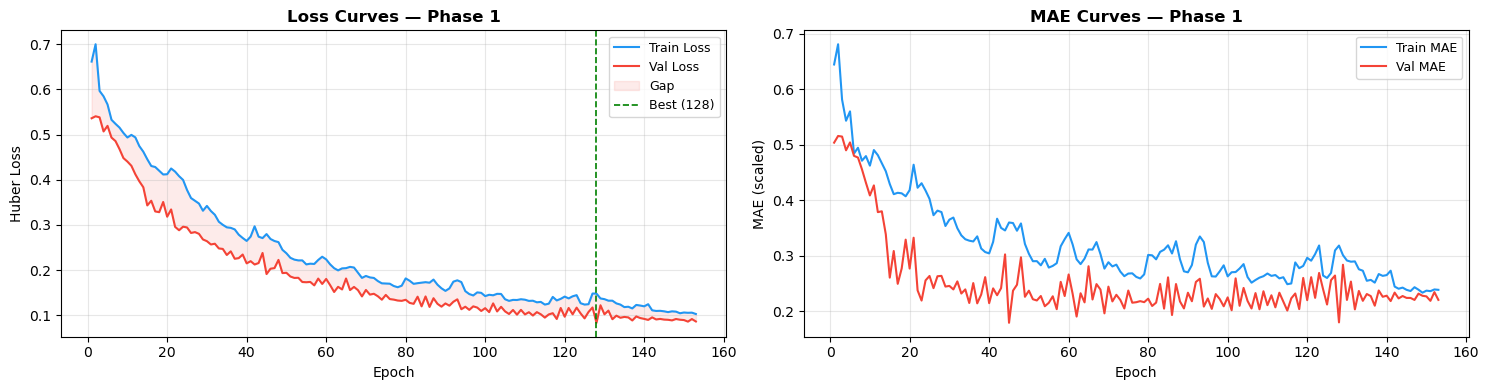

Saved: training_curves_v2.png


In [12]:
# ── 10a. Training Curves — Phase 1 ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

epochs_range = range(1, len(history.history["loss"]) + 1)
axes[0].plot(epochs_range, history.history["loss"],     label="Train Loss", color="#2196F3", lw=1.5)
axes[0].plot(epochs_range, history.history["val_loss"], label="Val Loss",   color="#F44336", lw=1.5)
axes[0].fill_between(epochs_range,
                     history.history["loss"],
                     history.history["val_loss"],
                     alpha=0.10, color="#F44336", label="Gap")
axes[0].axvline(best_epoch, color="green", linestyle="--", lw=1.2, label=f"Best ({best_epoch})")
axes[0].set_title("Loss Curves — Phase 1", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Huber Loss")
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history.history["mae"],     label="Train MAE", color="#2196F3", lw=1.5)
axes[1].plot(epochs_range, history.history["val_mae"], label="Val MAE",   color="#F44336", lw=1.5)
axes[1].set_title("MAE Curves — Phase 1", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE (scaled)")
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/figures/training_curves_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: training_curves_v2.png")


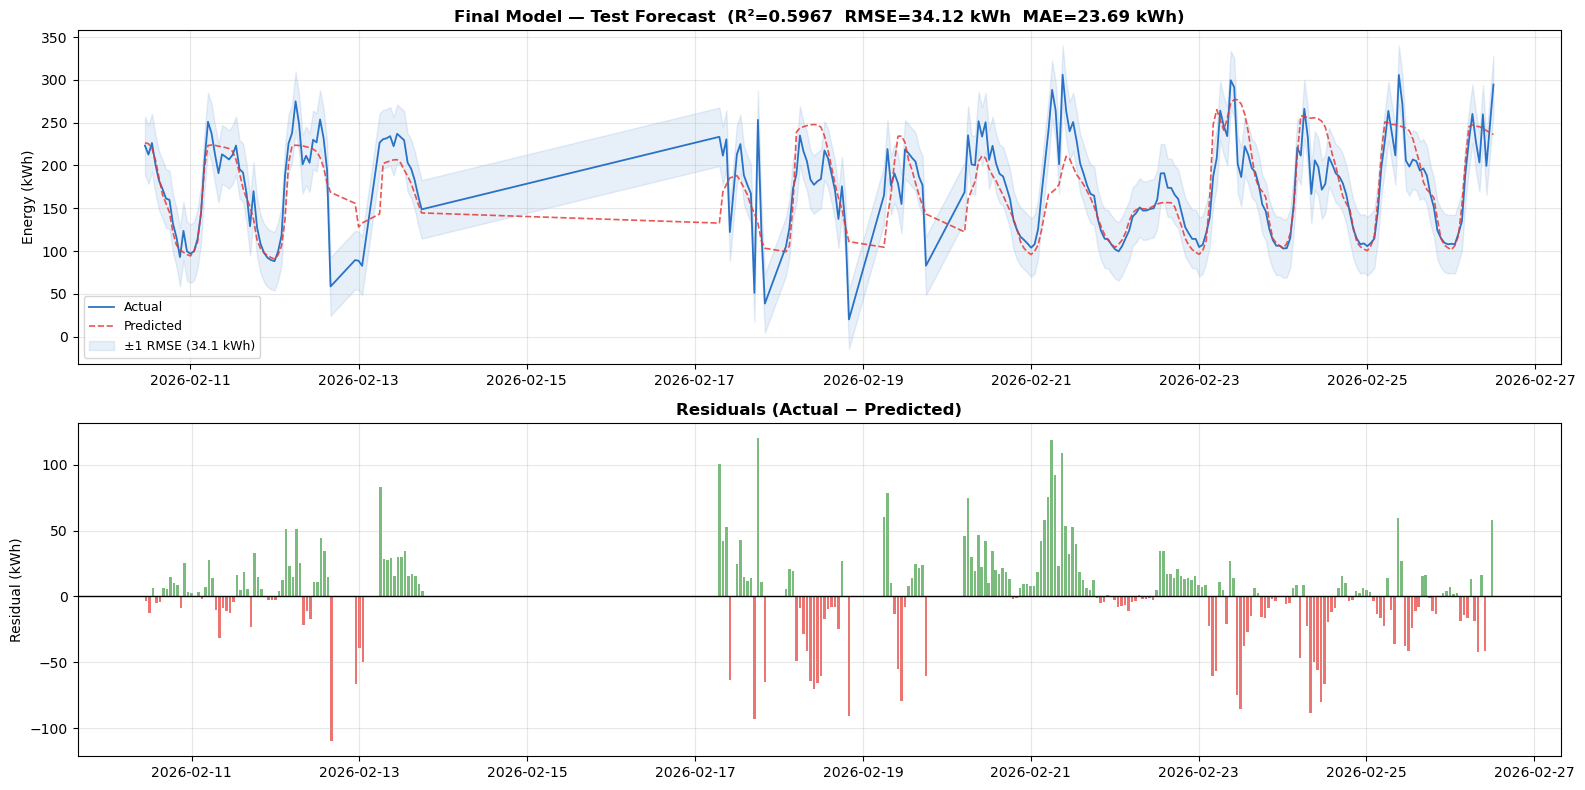

Saved: test_forecast_v2.png


In [13]:
# ── 10b. Predicted vs Actual — Full Test Period ───────────────────────────────
test_index = test_df.index[LOOK_BACK:]

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

axes[0].plot(test_index, y_true, label="Actual",    color="#1565C0", lw=1.3, alpha=0.9)
axes[0].plot(test_index, y_pred, label="Predicted", color="#E53935", lw=1.2, linestyle="--", alpha=0.85)
axes[0].fill_between(test_index, y_true - rmse, y_true + rmse,
                     alpha=0.10, color="#1565C0", label=f"±1 RMSE ({rmse:.1f} kWh)")
axes[0].set_title(f"Final Model — Test Forecast  (R²={r2:.4f}  RMSE={rmse:.2f} kWh  MAE={mae:.2f} kWh)",
                  fontsize=12, fontweight="bold")
axes[0].set_ylabel("Energy (kWh)"); axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

residuals = y_true - y_pred
axes[1].bar(test_index, residuals,
            color=np.where(residuals >= 0, "#43A047", "#E53935"), width=0.03, alpha=0.7)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Residuals (Actual − Predicted)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Residual (kWh)"); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/figures/test_forecast_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: test_forecast_v2.png")


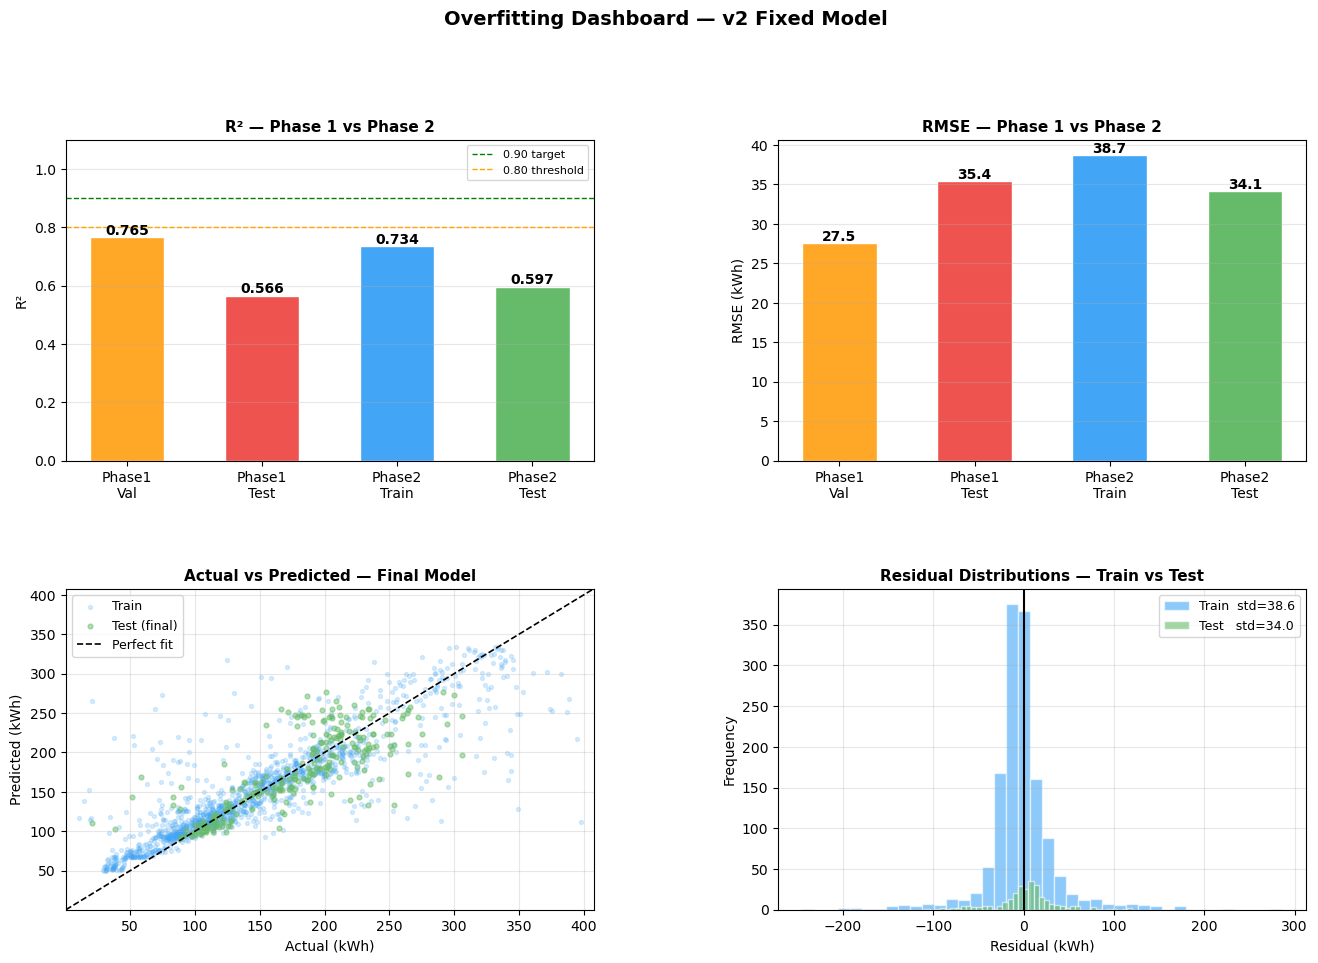

Saved: overfitting_dashboard_v2.png


In [14]:
# ── 10c. Overfitting Dashboard ────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.40, wspace=0.35)

# R² bars
ax1 = fig.add_subplot(gs[0, 0])
labels_bar = ["Phase1\nVal", "Phase1\nTest", "Phase2\nTrain", "Phase2\nTest"]
r2_vals    = [m_p1_val["R2"], m_p1_test["R2"], m_p2_train["R2"], m_p2_test["R2"]]
bar_colors = ["#FFA726", "#EF5350", "#42A5F5", "#66BB6A"]
bars = ax1.bar(labels_bar, r2_vals, color=bar_colors, edgecolor="white", width=0.55)
for b, v in zip(bars, r2_vals):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
             f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
ax1.axhline(0.9, color="green",  linestyle="--", lw=1, label="0.90 target")
ax1.axhline(0.8, color="orange", linestyle="--", lw=1, label="0.80 threshold")
ax1.set_ylim(0, 1.1); ax1.set_ylabel("R²")
ax1.set_title("R² — Phase 1 vs Phase 2", fontsize=11, fontweight="bold")
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3, axis="y")

# RMSE bars
ax2 = fig.add_subplot(gs[0, 1])
rmse_vals = [m_p1_val["RMSE"], m_p1_test["RMSE"], m_p2_train["RMSE"], m_p2_test["RMSE"]]
bars2 = ax2.bar(labels_bar, rmse_vals, color=bar_colors, edgecolor="white", width=0.55)
for b, v in zip(bars2, rmse_vals):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
             f"{v:.1f}", ha="center", fontsize=10, fontweight="bold")
ax2.set_ylabel("RMSE (kWh)")
ax2.set_title("RMSE — Phase 1 vs Phase 2", fontsize=11, fontweight="bold")
ax2.grid(True, alpha=0.3, axis="y")

# Scatter — actual vs predicted
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(p2_tr_true, p2_tr_pred, alpha=0.2, s=8,  color="#42A5F5", label="Train")
ax3.scatter(y_true,     y_pred,     alpha=0.5, s=12, color="#66BB6A", label="Test (final)")
lims = [min(p2_tr_true.min(), y_true.min()) - 10,
        max(p2_tr_true.max(), y_true.max()) + 10]
ax3.plot(lims, lims, "k--", lw=1.2, label="Perfect fit")
ax3.set_xlim(lims); ax3.set_ylim(lims)
ax3.set_xlabel("Actual (kWh)"); ax3.set_ylabel("Predicted (kWh)")
ax3.set_title("Actual vs Predicted — Final Model", fontsize=11, fontweight="bold")
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

# Residual distribution
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(p2_tr_true - p2_tr_pred, bins=40, alpha=0.6, color="#42A5F5",
         label=f"Train  std={np.std(p2_tr_true-p2_tr_pred):.1f}", edgecolor="white")
ax4.hist(residuals, bins=40, alpha=0.6, color="#66BB6A",
         label=f"Test   std={np.std(residuals):.1f}", edgecolor="white")
ax4.axvline(0, color="black", lw=1.5)
ax4.set_xlabel("Residual (kWh)"); ax4.set_ylabel("Frequency")
ax4.set_title("Residual Distributions — Train vs Test", fontsize=11, fontweight="bold")
ax4.legend(fontsize=9); ax4.grid(True, alpha=0.3)

plt.suptitle("Overfitting Dashboard — v2 Fixed Model", fontsize=14, fontweight="bold", y=1.01)
plt.savefig("../outputs/figures/overfitting_dashboard_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: overfitting_dashboard_v2.png")


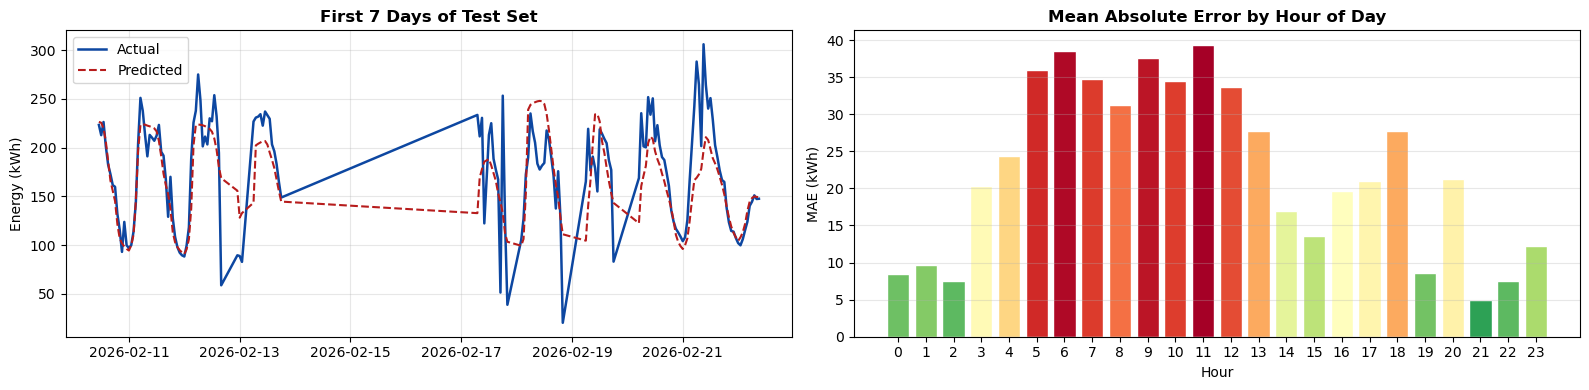

Peak error at hour 11:00  (39.34 kWh)


In [15]:
# ── 10d. 7-Day Zoom + Hourly Error Profile ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# 7-day zoom
N_ZOOM = min(168, len(y_true))
axes[0].plot(test_index[:N_ZOOM], y_true[:N_ZOOM],
             label="Actual",    color="#0D47A1", lw=1.8)
axes[0].plot(test_index[:N_ZOOM], y_pred[:N_ZOOM],
             label="Predicted", color="#B71C1C", lw=1.5, linestyle="--")
axes[0].set_title("First 7 Days of Test Set", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Energy (kWh)"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Error by hour of day
test_hours = test_index[:len(y_true)].hour
err_df = pd.DataFrame({"hour": test_hours, "abs_error": np.abs(residuals)})
hourly_err = err_df.groupby("hour")["abs_error"].mean()
cmap_vals  = hourly_err.values / hourly_err.max()
axes[1].bar(hourly_err.index, hourly_err.values,
            color=plt.cm.RdYlGn_r(cmap_vals), edgecolor="white")
axes[1].set_title("Mean Absolute Error by Hour of Day", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("MAE (kWh)")
axes[1].set_xticks(range(24)); axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("../outputs/figures/zoom_and_hourly_error_v2.png", dpi=150, bbox_inches="tight")
plt.show()
peak_hr = hourly_err.idxmax()
print(f"Peak error at hour {peak_hr:02d}:00  ({hourly_err[peak_hr]:.2f} kWh)")


## 10 · Save Model & Predictions

In [16]:
# ── 11. Save ──────────────────────────────────────────────────────────────────
import pickle

def safe_save_csv(dataframe, path):
    from datetime import datetime
    paths = [path, path.replace(".csv", f"_{datetime.now().strftime('%H%M%S')}.csv")]
    for p in paths:
        try:
            dataframe.to_csv(p, index=False)
            return p
        except PermissionError:
            print(f"⚠️  {p} locked, trying fallback...")
    raise PermissionError("Close the CSV in Excel and re-run.")

# Save final model
model_final.save("../models/lstm_energy_model_v2.keras")
print("✅ Model saved       →  lstm_energy_model_v2.keras")

# Save scalers
with open("../models/feature_scaler_v2.pkl", "wb") as f: pickle.dump(feature_scaler, f)
with open("../models/target_scaler_v2.pkl",  "wb") as f: pickle.dump(target_scaler,  f)
print("✅ Scalers saved     →  feature_scaler_v2.pkl | target_scaler_v2.pkl")

# Save predictions
pred_df = pd.DataFrame({
    "timestamp"  : test_index[:len(y_true)],
    "actual_kwh" : y_true,
    "pred_kwh"   : y_pred,
    "residual"   : residuals,
    "abs_error"  : np.abs(residuals),
})
saved = safe_save_csv(pred_df, "../outputs/tables/lstm_predictions_v2.csv")
print(f"✅ Predictions saved →  {saved}")

print(f"\n{'='*45}")
print(f"  FINAL RESULTS (v2 model)")
print(f"{'='*45}")
print(f"  R²   = {r2:.4f}")
print(f"  RMSE = {rmse:.4f} kWh")
print(f"  MAE  = {mae:.4f} kWh")
print(f"  MAPE = {mape:.2f}%")
print(f"{'='*45}")


✅ Model saved       →  lstm_energy_model_v2.keras
✅ Scalers saved     →  feature_scaler_v2.pkl | target_scaler_v2.pkl
✅ Predictions saved →  lstm_predictions_v2.csv

  FINAL RESULTS (v2 model)
  R²   = 0.5967
  RMSE = 34.1199 kWh
  MAE  = 23.6854 kWh
  MAPE = 15.78%


## 11 · If R² Is Still Low — Next Steps

### ✅ Changes Already Applied in v2
- LOOK_BACK: 24 → **48** (2-day history window)
- dropout: 0.30 → **0.45**
- L2 reg: 1e-4 → **5e-4**
- LR: 1e-3 → **5e-4**
- Batch: 32 → **64**
- LSTM units reduced: 128/64 → **96/48**
- **Two-phase training**: tune on train/val → retrain final on train+val

### 🔧 If Test R² < 0.70 after v2
The issue is likely **distribution shift** between training period (Sep–Jan) and test period (Feb) — not a model problem.

| Fix | How |
|---|---|
| Add more recent data | Extend dataset to include more Feb data |
| Add month/season interaction features | `month × out_temp`, `month × hour_sin` |
| Increase `LOOK_BACK` to 72 or 96 | Even more history context |
| Use walk-forward validation | Re-train model every week on rolling window |

### 🧪 Reload Models
```python
from tensorflow import keras
model_final = keras.models.load_model("lstm_energy_model_v2.keras")
```
